# Modelle – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 3

In diesem Notebook wir vergleichen drei Algorithmen. Alle bekommen die selben Features und die selbe Cross-Validation, damit der Vergleich ist fair. Den besten Algorithmus wir tunen danach noch und am Ende speichern wir das Modell ab.

Die Daten kommen aus data/fd_features.csv, das wurde gemacht in 06_features.ipynb. Der Split steht in data/fd_split.csv und für die bewertung nehmen wir die Funktionen aus fd_utils.py, so wie die anderen Notebooks auch.

Vorher ausführen: die Notebooks 04 bis 06, weil sonst fehlen die Dateien in data/ und das Baseline-Modell in models/.

Achtung, das ganze Notebook braucht mehr als 10 Minuten, vorallem das Tuning weiter unten.

## 1. Setup

In [1]:
# Die Bibliotheken die wir brauchen in dem Notebook
from pathlib import Path

import joblib                      # zum laden und speichern von Modellen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Alles von scikit-learn: Vorbereitung, die drei Algorithmen und die Suche für den Tuning
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Unsere gemeinsame Sachen: der Zufalls-Seed, die 5 Folds und die Funktion für Bewertung
from fd_utils import RANDOM_STATE, cv, evaluate_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)   # damit man sieht alle Spalten bei breiten Tabellen

# Ordner für die Daten und die Modelle
DATA_DIR = Path("data")
MODEL_DIR = Path("models")

## Daten laden
Wir laden die Tabelle mit den Features und die Tabelle mit den Split. In der Split-Tabelle steht für jeden Kunde, ob er gehört zu "train" oder zu "test". Die zwei Tabellen wir verbinden über die client_id.

In [2]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")

# Die Split-Spalte an die Features dran hängen mit left, damit kein Kunde geht verloren
df = df.merge(df_split, on="client_id", how="left")

# nur die Kunden aus den Train-Teil behalten
df_train = df[df["split"] == "train"]

# Diese Spalten sind keine Features: die ID, das Datum, der Split und natürlich das Ziel selber
nicht_features = ["client_id", "creation_date", "split", "target"]
X_train = df_train.drop(columns=nicht_features)
y_train = df_train["target"]

print("X_train:", X_train.shape)
print("Betrugsquote:", round(y_train.mean(), 4))

X_train: (108394, 30)
Betrugsquote: 0.0558


Wir haben also 108.394 Kunden mit 30 Spalten und die Betrugsquote ist ungefähr 5,6 % also 0,0558. Das ist sehr unausgeglichen, darum class_weight ist später wichtig.

Wie in 05_baseline.ipynb wir arbeiten hier nur mit den **Train-Teil** und mit Cross-Validation. Der Test-Teil wird gar nicht geladen in diesem Notebook, damit wir nicht aus versehen darauf Optimieren.

### 2 · Baseline zum Vergleich
Zuerst brauchen wir eine Zahl, mit die wir können vergleichen. Das ist die logistische Regression aus 05_baseline.ipynb, sie benutzt nur die Spalten aus fd_cleaned.csv. Die Pipeline sucht ihre Spalten selber aus, deswegen sie funktioniert auch mit der größeren Tabelle von hier, ohne dass wir etwas ändern müssen.

In [3]:
# das gespeicherte Baseline-Modell laden, es wurde gespeichert in 05_baseline.ipynb
baseline = joblib.load(MODEL_DIR / "fd_baseline.joblib")

# evaluate_cv macht die Cross-Validation und gibt zurück eine Tabelle mit einer Zeile.
# Das ist die erste Zeile von unsere Ergebnis-Tabelle, die anderen Modelle kommen dann darunter.
ergebnisse = evaluate_cv(baseline, X_train, y_train, "Baseline: LogReg (fd_cleaned)")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


## 3) Modell 1: logistische Regression mit den neuen Features
Die Vorbereitung ist das gleiche wie in der Baseline, nur jetzt mit alle neuen Spalten aus 06_features.ipynb.

Die Spalten teilen wir in drei Gruppen:
* **Kategorien** Bezirk, Kundenkategorie und Region: die werden mit One-Hot-Encoding zu 0/1 Spalten
* **schiefe Spalten**: alle Verbrauchs- und Sprung-Spalten sind sehr schief verteilt, es gibt wenige Kunden mit riesigen werten. Die bekommen zuerst log(1 + x) und werden dann skaliert
* **die restlichen Zahlen**: nur skalieren

In [4]:
# Gruppe 1: die Kategorien. Das Wort disrict ist kein Tippfehler von uns, die Spalte heisst wirklich so in den Daten
kategorien = ["disrict", "client_catg", "region"]

# Gruppe 2: schief verteilte Spalten, die bekommen das Logarithmus
schief = ["cons_median_elec", "cons_mean_elec", "cons_std_elec",
          "cons_median_gaz", "cons_mean_gaz", "cons_std_gaz",
          "month_median_elec", "month_std_elec", "month_median_gaz", "month_std_gaz",
          "max_drop", "max_rise", "mean_abs_change", "trend_ratio", "cv_elec", "cv_gaz"]

# Gruppe 3: alles was bleibt übrig, also Spalten die sind weder Kategorie noch schief
zahlen = []
for spalte in X_train.columns:
    if spalte not in kategorien and spalte not in schief:
        zahlen.append(spalte)

print("Zahlen ohne log:", zahlen)

Zahlen ohne log: ['n_invoices', 'n_counters', 'share_gas', 'share_zero', 'any_index_backwards', 'share_statue_not_ok', 'contract_age_years', 'active_years', 'share_remarque_6', 'share_remarque_8', 'share_remarque_9']


In [5]:
# Für die schiefen Spalten wir machen zwei Schritte hintereinander: erst `log(1 + x)`, dann skalieren.
# log1p statt log, weil es gibt viele Nullen und `log(0)` geht nicht.
log_und_skalieren = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

# Der ColumnTransformer schickt jede Gruppe von Spalten zu seine eigene Vorbereitung.
# handle_unknown / min_frequency: seltene Kategorien mit weniger als 100 Kunden kommen zusammen
# in eine Sammel-Spalte und unbekannte Kategorien machen später kein Fehler.
vorbereitung = ColumnTransformer([
    ("kategorien", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), kategorien),
    ("schief", log_und_skalieren, schief),
    ("zahlen", StandardScaler(), zahlen),
])

# Vorbereitung und Modell zusammen in einer Pipeline, so es wird in jedem Fold neu gefittet und wir haben kein Data Leakage
# class_weight="balanced" wegen der wenigen Betrugsfällen, max_iter=2000 damit es sicher Konvergiert
logreg = Pipeline([
    ("vorbereitung", vorbereitung),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

In [6]:
def ergebnis_dazu(tabelle, modell, name):
    # Bewertet ein Modell mit evaluate_cv auf X_train und y_train von oben
    # und hängt die neue Zeile an unten von der Ergebnis-Tabelle.
    neue_zeile = evaluate_cv(modell, X_train, y_train, name)
    tabelle = pd.concat([tabelle, neue_zeile])
    return tabelle


ergebnisse = ergebnis_dazu(ergebnisse, logreg, "LogReg: neue Features")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146


Die ROC-AUC geht von 0,804 auf 0,813, die neuen Features helfen also ein bisschen. Mehr dazu wir sehen unten beim Vergleich.

## Random Forest
Das zweite Modell. Die Bäume brauchen kein Skalieren und auch kein Logarithmus, weil ein Baum fragt nur "ist der Wert größer oder kleiner als x". Die Codes von Region und Bezirk der Baum kann direkt benutzen als Zahlen, deshalb wir geben hier X_train einfach so rein ohne die Vorbereitung von oben.

In [7]:
# n_estimators=200          -> 200 Bäume
# min_samples_leaf=20       -> in jedem Blatt müssen sein mindestens 20 Kunden, damit die Bäume
#                              nicht jeden einzelnen Kunden auswendig lernen, das ist Overfitting
# class_weight="balanced"   -> wegen die wenigen Betrugsfälle, sonst der Wald sagt fast immer "kein Betrug"
# n_jobs=-1                 -> alle Prozessor-Kerne zu benutzen, das geht mehr schnell
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

ergebnisse = ergebnis_dazu(ergebnisse, rf, "Random Forest")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197


### Modell 3 - AdaBoost
AdaBoost kennen wir aus week07, das war Ensemble-Methoden. Es baut viele sehr kleine Bäume nacheinander und jeder neuer Baum schaut sich besonders die Kunden an bei denen die Bäume davor falsch lagen.

AdaBoost hat kein class_weight. Für die ROC-AUC das ist aber egal, weil die ROC-AUC bewertet nur die reihenfolge von den Kunden und nicht der Schwelle.

In [8]:
# 200 kleine Bäume nacheinander, der Rest sind Standard-Einstellung
ada = AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE)

ergebnisse = ergebnis_dazu(ergebnisse, ada, "AdaBoost")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142
LogReg: neue Features,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343


## Vergleich von den Modellen
Jetzt alle vier Modelle zusammen, einmal als Balken und einmal als Tabelle. Sortiert ist nach ROC-AUC.

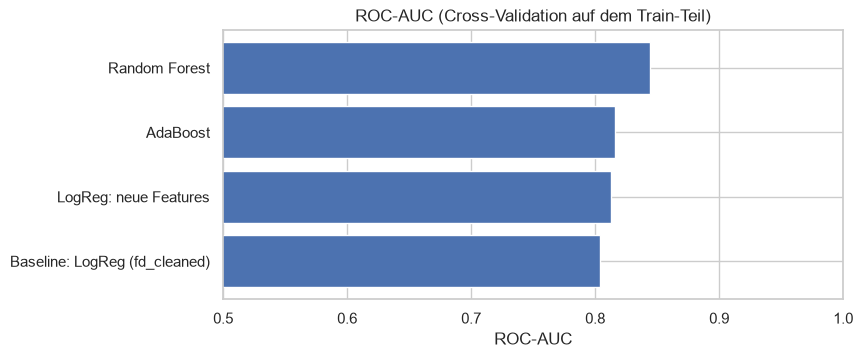

,ROC-AUC,ROC-AUC std,Recall,Precision
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
LogReg: neue Features,0.813,0.006,0.750,0.146
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


In [9]:
# ROC-AUC aufsteigend sortieren, dann das beste Modell steht ganz oben im Balkendiagramm
auc_sortiert = ergebnisse["ROC-AUC"].sort_values()

plt.figure(figsize=(8, 3.5))
plt.barh(auc_sortiert.index, auc_sortiert.values)
plt.title("ROC-AUC (Cross-Validation auf dem Train-Teil)")
plt.xlabel("ROC-AUC")
plt.xlim(0.5, 1)   # 0.5 ist raten, darunter es gibt nichts interessantes
plt.show()

# und die tabelle dazu, das beste Modell zuerst
ergebnisse.sort_values("ROC-AUC", ascending=False)

**Was fällt auf?**
* Mit den neuen Features die logistische Regression wird etwas besser, von 0,804 auf 0,813.
* Der **Random Forest ist am besten** mit 0,844. Bäume kommen besser klar mit schiefen Werten, mit Ausreißer und mit Zusammenhängen wie "erst hoch, dann runter". Das haben wir gesehen bei den Nullrechnungen in EDA, Teil I.
* AdaBoost mit 0,816 ist nur knapp über der logistischen Regression. Der Recall von 1 % heißt aber nicht, dass AdaBoost schlecht sortiert: ohne class_weight sagt es bei der Schwelle 0,5 fast nie "Betrug". Für den Vergleich zählt die ROC-AUC.
* Die Unterschiede zwischen den Folds sind klein, std 0,004–0,007, darum die Reihenfolge ist kein Zufall.
* Bei Recall und Precision man sieht auch ein Unterschied: die logistische Regression findet mehr Betrüger mit Recall 0,750, aber der Random Forest hat weniger falsche Alarme mit Precision 0,197 statt 0,146.

**Entscheidung:** Wir tunen den Random Forest, weil er hat die beste ROC-AUC.

## 7 Tuning des Random Forest
Wir probieren mit RandomizedSearchCV, wie in week06, 10 zufällige Kombinationen von Hyperparameter aus. Jede Kombination wird bewertet mit den selben 5 Folds. Das dauert ein paar Minuten, also nicht wundern.

In [10]:
# Der Parameterraum, von dem wir ziehen zufällig:
#   n_estimators      = Anzahl Bäume
#   max_depth         = wie tief ein Baum darf werden, None heißt unbegrenzt
#   min_samples_leaf  = wieviele Kunden mindestens sein müssen in einem Blatt
#   max_features      = wie viele Spalten jeder Baum darf ausprobieren bei eine Frage
#                       sqrt ist die Wurzel aus der Anzahl Spalten und 0.3 sind 30 % der Spalten
parameter_raum = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features": ["sqrt", 0.3, 0.5],
}

# Der Wald der wird getunt. class_weight und random_state sind fest, der Rest kommt aus der Parameterraum.
rf_fuer_tuning = RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)

# n_iter=10 -> 10 Kombinationen, bewertet wird mit ROC-AUC und mit unsere 5 Folds aus fd_utils
rs = RandomizedSearchCV(
    rf_fuer_tuning,
    parameter_raum,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rs.fit(X_train, y_train)

print("Beste CV-ROC-AUC:", round(rs.best_score_, 3))
print("Beste Parameter: ", rs.best_params_)

Beste CV-ROC-AUC: 0.847
Beste Parameter:  {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 20}


In [11]:
# Wir schauen an die 5 besten Kombinationen.
# In cv_results_ steht eine Zeile für jede von die 10 Kombinationen, aber wir brauchen nur ein paar Spalten davon.
tuning = pd.DataFrame(rs.cv_results_)
spalten = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
           "param_max_features", "mean_test_score", "std_test_score"]

tuning_top5 = tuning[spalten].sort_values("mean_test_score", ascending=False).head()
tuning_top5.round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score
2,300,20,20,0.3,0.8467,0.0045
3,300,20,10,0.3,0.8463,0.0049
1,100,20,20,0.3,0.8458,0.0042
6,200,20,10,0.3,0.8458,0.0045
9,100,10,20,0.5,0.8449,0.0042


In [12]:
# Die Suche gibt uns nur der ROC-AUC. Damit das getunte Modell passt in unsere Tabelle,
# wir bewerten es nochmal mit evaluate_cv, dann haben wir auch Recall und Precision.
rf_tuned = rs.best_estimator_

ergebnisse = ergebnis_dazu(ergebnisse, rf_tuned, "Random Forest (getunt)")
ergebnisse.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,ROC-AUC std,Recall,Precision
Random Forest (getunt),0.847,0.005,0.664,0.202
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
LogReg: neue Features,0.813,0.006,0.750,0.146
Baseline: LogReg (fd_cleaned),0.804,0.007,0.743,0.142


**Was fällt auf?**
* Das Tuning bringt nur wenig: 0,844 → **0,847**. Die Einstellungen die wir haben genommen vorher, waren schon gut.
* Recall und Precision ändern sich auch fast nicht, Recall 0,667 → 0,664 und Precision 0,197 → 0,202.
* Bei den besten vier Kombinationen ist max_depth 20 und max_features 0,3. Die Bäume dürfen also nicht beliebig tief werden und schauen bei jeder Frage nur auf einen Teil von die Spalten. Erst die fünfte Kombination hat andere Werte, nämlich Tiefe 10 und 0,5.
* Die besten Kombinationen liegen sehr nah zusammen, von 0,8467 bis 0,8449. Das ist kleiner als die Streuung zwischen die Folds. Man soll also nicht zu viel Lesen in die einzelne Parameter.

# 8 · Bestes Modell speichern
RandomizedSearchCV hat das beste Modell am ende schon auf den ganzen Train-Teil trainiert, das macht es automatisch. Wir müssen also nicht nochmal fitten und speichern es direkt für 08_fehleranalyse.ipynb und 09_abschluss.ipynb. Die Ergebnis-Tabelle speichern wir auch, dann die anderen Notebooks müssen nicht alles neu rechnen.

In [13]:
# Ordner anlegen falls es gibt ihn noch nicht
MODEL_DIR.mkdir(exist_ok=True)

# das getunte Modell und die Tabelle mit alle CV-Ergebnisse speichern
joblib.dump(rf_tuned, MODEL_DIR / "fd_best_model.joblib")
ergebnisse.to_csv(MODEL_DIR / "cv_ergebnisse.csv")

print("Gespeichert: models/fd_best_model.joblib und models/cv_ergebnisse.csv")

Gespeichert: models/fd_best_model.joblib und models/cv_ergebnisse.csv


## Fazit
Die ROC-AUC aus der Cross-Validation, von das schlechteste bis zum besten:

* Baseline: LogReg (fd_cleaned): 0,804
* LogReg: neue Features: 0,813
* AdaBoost: 0,816
* Random Forest: 0,844
* **Random Forest (getunt): 0,847**

Das beste Modell schlägt die Baseline um 0,043 ROC-AUC. Der größte Schritt kommt dabei von dem Wechsel zu den Random Forest, die neuen Features und das Tuning bringen jeweils nur wenig.

Das Modell ist gespeichert als models/fd_best_model.joblib. Weiter geht es mit 08_fehleranalyse.ipynb.